# Лабораторная работа №1: регрессия на данных Wine Quality

**Задача.** Предсказать экспертную оценку качества вина (`quality`, целое число от 0 до 10) по физико-химическим показателям.
**Основная метрика:** RMSE (порог по заданию: RMSE < 0.70). **Дополнительная:** MAE.

**Что делается в работе:** первичный анализ данных → разбиение train/test → baseline → линейная регрессия, Random Forest, Gradient Boosting → честное сравнение → анализ feature importance → анализ ошибок лучшей модели.

### Какие данные используются
Датасет Wine Quality из UCI состоит из двух файлов: красное (`winequality-red.csv`, 1599 вин) и белое (`winequality-white.csv`, 4898 вин) вино. В работе они **объединены в одну выборку** (6497 вин), а тип вина закодирован бинарным признаком `is_red`. Причины:
* в задании речь идёт о датасете Wine Quality целиком, а не об одной из его частей;
* больше объектов означает более устойчивую оценку качества, особенно для редких значений `quality`;
* различие красного и белого вина само по себе информативно, и модель должна иметь возможность его использовать.

Файлы лежат в `data/` в исходном виде (разделитель `;`), без изменений.

### Автоматическая подготовка окружения
Первая ячейка ниже: (1) доустанавливает недостающие библиотеки **в то окружение, в котором запущен этот ноутбук** (через `sys.executable`, то есть в ваш `.venv`, если ядро выбрано оттуда); (2) если файлов данных нет рядом с ноутбуком, скачивает их в папку `data/`. Если всё уже установлено и данные на месте, ячейка ничего не делает. После первой установки пакетов может понадобиться перезапустить ядро (Kernel → Restart) и запустить ноутбук ещё раз.

In [1]:
import sys, subprocess, importlib.util, urllib.request, zipfile, io
from pathlib import Path

# --- 1. Библиотеки: ставим только то, чего не хватает, в текущее окружение ---
REQUIRED = {"numpy": "numpy", "pandas": "pandas", "scipy": "scipy", "sklearn": "scikit-learn",
            "matplotlib": "matplotlib", "seaborn": "seaborn"}
missing = [pip_name for mod, pip_name in REQUIRED.items() if importlib.util.find_spec(mod) is None]
if missing:
    print("Устанавливаю:", ", ".join(missing), "->", sys.executable)
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *missing])
    print("Готово. Если дальше появится ImportError, перезапустите ядро и запустите ноутбук заново.")
else:
    print("Все библиотеки уже установлены.")

# --- 2. Данные: ищем data/ рядом с ноутбуком, иначе скачиваем ---
FILES = ["winequality-red.csv", "winequality-white.csv"]
SOURCES = [  # (описание, функция скачивания)
    ("UCI (zip)", "https://archive.ics.uci.edu/static/public/186/wine+quality.zip"),
    ("GitHub-зеркало", "https://raw.githubusercontent.com/shrikant-temburwar/Wine-Quality-Dataset/master/{name}"),
]

def has_data(root):
    return all((root / "data" / f).exists() for f in FILES)

ROOT = next((r for r in (Path("."), Path("..")) if has_data(r)), None)
if ROOT is None:
    ROOT = Path("..") if Path("../notebooks").exists() else Path(".")   # открыт из notebooks/ -> кладём в корень проекта
    (ROOT / "data").mkdir(exist_ok=True)
    for label, url in SOURCES:
        try:
            if url.endswith(".zip"):
                z = zipfile.ZipFile(io.BytesIO(urllib.request.urlopen(url, timeout=60).read()))
                for f in FILES:
                    (ROOT / "data" / f).write_bytes(z.read(f))
            else:
                for f in FILES:
                    (ROOT / "data" / f).write_bytes(urllib.request.urlopen(url.format(name=f), timeout=60).read())
            print(f"Данные скачаны ({label}) в {(ROOT / 'data').resolve()}")
            break
        except Exception as e:
            print(f"Не удалось скачать из источника «{label}»: {type(e).__name__}")
    if not has_data(ROOT):
        raise FileNotFoundError("Не удалось получить данные. Скачайте winequality-red.csv и winequality-white.csv "
                                "с https://archive.ics.uci.edu/dataset/186/wine+quality и положите в папку data/ рядом с ноутбуком.")
else:
    print("Данные найдены:", (ROOT / "data").resolve())

Все библиотеки уже установлены.
Данные найдены: /home/claude/wine_regression_lab/data


In [2]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

from sklearn.model_selection import train_test_split, KFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.preprocessing import StandardScaler, PolynomialFeatures, FunctionTransformer
from sklearn.pipeline import make_pipeline, Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import mean_squared_error, mean_absolute_error
from sklearn.inspection import permutation_importance
from scipy.stats import spearmanr

RANDOM_STATE = 42          # единый seed для всего эксперимента
TEST_SIZE = 0.20

DATA_DIR, FIG_DIR, RES_DIR = ROOT / "data", ROOT / "figures", ROOT / "results"   # ROOT определён в ячейке подготовки выше
FIG_DIR.mkdir(exist_ok=True); RES_DIR.mkdir(exist_ok=True)

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

def rmse(y_true, y_pred):
    return float(np.sqrt(mean_squared_error(y_true, y_pred)))

def mae(y_true, y_pred):
    return float(mean_absolute_error(y_true, y_pred))

def savefig(name):
    plt.tight_layout()
    plt.savefig(FIG_DIR / name, bbox_inches="tight")

## 1. Знакомство с данными

In [3]:
red = pd.read_csv(DATA_DIR / "winequality-red.csv", sep=";");   red["is_red"] = 1
white = pd.read_csv(DATA_DIR / "winequality-white.csv", sep=";"); white["is_red"] = 0
df = pd.concat([red, white], ignore_index=True)

FEATURES = [c for c in df.columns if c != "quality"]
print("Размер красного:", red.shape, "| белого:", white.shape, "| объединённого:", df.shape)
print("Пропусков:", int(df.isna().sum().sum()))
print("Полностью совпадающих строк (включая quality):", int(df.duplicated().sum()))
df.describe().T.round(3)

Размер красного: (1599, 13) | белого: (4898, 13) | объединённого: (6497, 13)
Пропусков: 0
Полностью совпадающих строк (включая quality): 1177


,count,mean,std,min,25%,50%,75%,max
fixed acidity,6497.0,7.215,1.296,3.800,6.400,7.000,7.700,15.900
volatile acidity,6497.0,0.340,0.165,0.080,0.230,0.290,0.400,1.580
citric acid,6497.0,0.319,0.145,0.000,0.250,0.310,0.390,1.660
residual sugar,6497.0,5.443,4.758,0.600,1.800,3.000,8.100,65.800
chlorides,6497.0,0.056,0.035,0.009,0.038,0.047,0.065,0.611
free sulfur dioxide,6497.0,30.525,17.749,1.000,17.000,29.000,41.000,289.000
total sulfur dioxide,6497.0,115.745,56.522,6.000,77.000,118.000,156.000,440.000
density,6497.0,0.995,0.003,0.987,0.992,0.995,0.997,1.039
pH,6497.0,3.219,0.161,2.720,3.110,3.210,3.320,4.010
sulphates,6497.0,0.531,0.149,0.220,0.430,0.510,0.600,2.000



**Вывод.** Выборка чистая: 6497 вин, 11 физико-химических признаков + бинарный `is_red`, пропусков нет. Два наблюдения влияют на дальнейшую работу.

1. **Масштабы признаков несопоставимы.** `density` лежит в диапазоне 0.987–1.039 (std ≈ 0.003), а `total sulfur dioxide` — 6–440 (std ≈ 57). Для деревьев это не проблема, но для линейной модели коэффициенты на «сырых» признаках сравнивать нельзя (см. раздел 5.1).
2. **1177 строк (≈18 %) — полные дубликаты** (включая `quality`). Для вина это не обязательно ошибка: лабораторные показатели округлены, и разные партии вполне могут дать одинаковый вектор. Поэтому дубликаты **не удалялись** — это изменило бы распределение данных. Но у них есть побочный эффект для оценки качества: при случайном разбиении копия тестового вина часто попадает в train. Насколько это искажает метрики, измерено в разделе 8.


### 1.1 Распределение целевой переменной

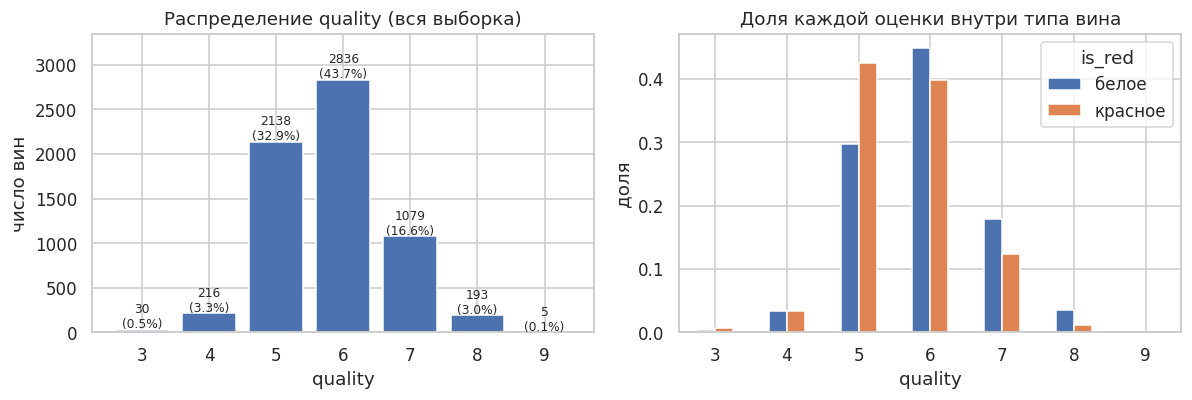

count    6497.000
mean        5.818
std         0.873
min         3.000
25%         5.000
50%         6.000
75%         6.000
max         9.000

Среднее quality: красное = 5.636 | белое = 5.878


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8))
vc = df["quality"].value_counts().sort_index()
ax[0].bar(vc.index, vc.values, color="#4C72B0")
for x, v in vc.items():
    ax[0].text(x, v + 20, f"{v}\n({v/len(df):.1%})", ha="center", fontsize=8)
ax[0].set_title("Распределение quality (вся выборка)"); ax[0].set_xlabel("quality"); ax[0].set_ylabel("число вин")
ax[0].set_ylim(0, vc.max() * 1.18)

pd.crosstab(df["quality"], df["is_red"].map({1: "красное", 0: "белое"}), normalize="columns").plot(kind="bar", ax=ax[1], rot=0)
ax[1].set_title("Доля каждой оценки внутри типа вина"); ax[1].set_xlabel("quality"); ax[1].set_ylabel("доля")
savefig("01_quality_distribution.png"); plt.show()

print(df["quality"].describe().round(3).to_string())
print("\nСреднее quality: красное =", round(red["quality"].mean(), 3), "| белое =", round(white["quality"].mean(), 3))


**Вывод.** Целевая переменная дискретна и сосредоточена в центре: оценки 5 и 6 дают **≈77 % выборки**, среднее 5.82, std 0.87. Крайние оценки редки: `quality = 3` — 30 вин (0.5 %), `quality = 9` — всего 5 вин (0.08 %). Значений ниже 3 и выше 9 нет вообще.

Что это значит для моделирования:
* Любая модель будет «уверенно» предсказывать значения около 5–6 и плохо — хвосты. Хвосты ошибок надо смотреть отдельно (раздел 8), а не только общий RMSE.
* При таком распределении простая константа уже даёт неплохой MAE, так что разрыв «модель − baseline» нужно оценивать аккуратно.
* Из-за редких классов разбиение на train/test выполняется со **стратификацией по `quality`**, иначе редкие оценки могут целиком оказаться в одной из частей.
* Красные вина в среднем оценены чуть ниже белых (5.64 против 5.88). Разница небольшая (≈0.24 балла), поэтому один только тип вина качество почти не объясняет.


### 1.2 Распределения признаков и выбросы

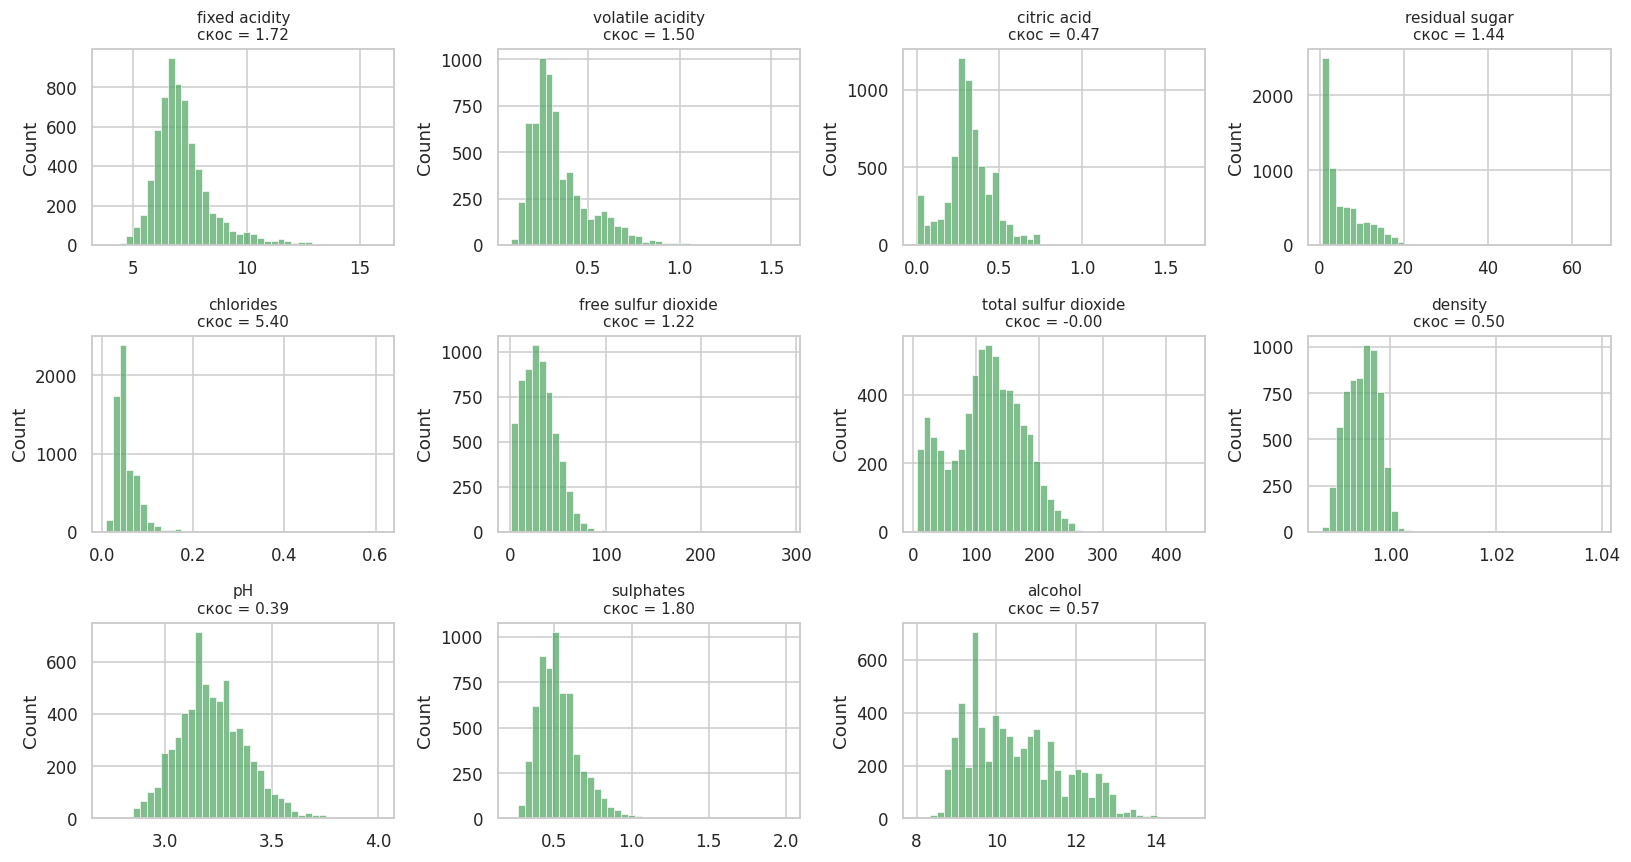

Асимметрия признаков (skew):
chlorides               5.40
sulphates               1.80
fixed acidity           1.72
volatile acidity        1.50
residual sugar          1.44
free sulfur dioxide     1.22
alcohol                 0.57
density                 0.50
citric acid             0.47
pH                      0.39
total sulfur dioxide   -0.00


In [5]:
num_feats = [f for f in FEATURES if f != "is_red"]
fig, axes = plt.subplots(3, 4, figsize=(15, 8))
for ax, f in zip(axes.ravel(), num_feats):
    sns.histplot(df[f], bins=40, ax=ax, color="#55A868")
    ax.set_title(f"{f}\nскос = {df[f].skew():.2f}", fontsize=10); ax.set_xlabel("")
for ax in axes.ravel()[len(num_feats):]:
    ax.axis("off")
savefig("02_feature_distributions.png"); plt.show()

skew = df[num_feats].skew().sort_values(ascending=False).round(2)
print("Асимметрия признаков (skew):"); print(skew.to_string())


**Вывод.** Большинство признаков имеют асимметричные распределения с правым «хвостом»: сильнее всего `chlorides` (skew ≈ 5.4), затем `sulphates`, `fixed acidity`, `volatile acidity`, `residual sugar`. Максимумы далеко отстоят от основной массы (например, `residual sugar` до 65.8 при медиане 3.0, `free sulfur dioxide` до 289 при медиане 29).

Эти значения нельзя автоматически считать ошибками: сладкие или особо стабилизированные вина действительно существуют. Поэтому **выбросы не удалялись** и данные не преобразовывались логарифмом: так все три модели сравниваются на одинаковых сырых признаках, а деревья нечувствительны к монотонным преобразованиям и выбросам. Для линейной регрессии это ограничение (она чувствительна к выбросам и скошенности), и это один из возможных путей улучшения.


### 1.3 Связь признаков с качеством

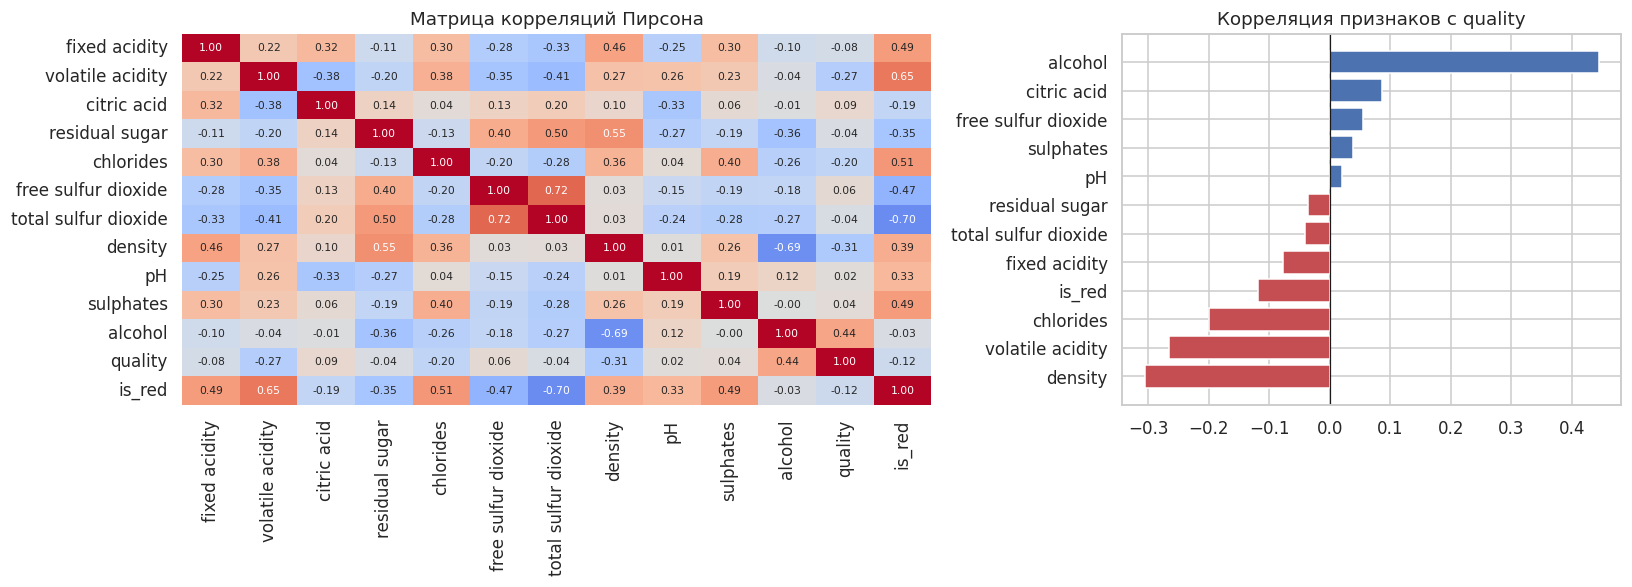

Корреляция Пирсона / Спирмена с quality:
                      pearson  spearman
alcohol                 0.444     0.447
citric acid             0.086     0.106
free sulfur dioxide     0.055     0.087
sulphates               0.038     0.030
pH                      0.020     0.033
residual sugar         -0.037    -0.017
total sulfur dioxide   -0.041    -0.055
fixed acidity          -0.077    -0.098
is_red                 -0.119    -0.123
chlorides              -0.201    -0.295
volatile acidity       -0.266    -0.258
density                -0.306    -0.323


In [6]:
corr = df.corr(numeric_only=True)
fig, ax = plt.subplots(1, 2, figsize=(15, 5.5), gridspec_kw={"width_ratios": [1.5, 1]})
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, vmin=-1, vmax=1,
            annot_kws={"size": 7}, cbar=False, ax=ax[0])
ax[0].set_title("Матрица корреляций Пирсона")

cq = corr["quality"].drop("quality").sort_values()
ax[1].barh(cq.index, cq.values, color=np.where(cq.values > 0, "#4C72B0", "#C44E52"))
ax[1].set_title("Корреляция признаков с quality"); ax[1].axvline(0, color="k", lw=.8)
savefig("03_correlations.png"); plt.show()

sp = df[FEATURES].apply(lambda s: spearmanr(s, df["quality"])[0]).sort_values()
print("Корреляция Пирсона / Спирмена с quality:")
print(pd.DataFrame({"pearson": cq, "spearman": sp}).loc[cq.index[::-1]].round(3).to_string())


**Вывод.**
* **`alcohol` — единственный признак с заметной линейной связью с качеством** (r ≈ +0.44; Спирмен 0.45): чем крепче вино, тем в среднем выше оценка. Это значит, что один признак объясняет ≈ 20 % дисперсии `quality` (r² ≈ 0.2), и его обязательно нужно использовать.
* Далее по модулю: `density` (−0.31), `volatile acidity` (−0.27), `chlorides` (−0.20 по Пирсону, но −0.30 по Спирмену). Для `volatile acidity` связь хорошо объяснима: это летучие (уксусные) кислоты, избыток которых придаёт вину запах уксуса. Для `chlorides` разница между Пирсоном и Спирменом указывает на влияние выбросов и скошенности: связь монотонная, но не линейная.
* Остальные признаки линейно почти не связаны с качеством (|r| < 0.12). Но **слабая линейная связь не означает бесполезности признака**: `citric acid` и `free sulfur dioxide` имеют |Спирмен| выше, чем |Пирсон|, а зависимость может быть немонотонной (оптимальный диапазон) или проявляться только во взаимодействии с другими признаками. Это проверяется моделями с нелинейностью (раздел 7).
* Практический вывод: потолок качества линейной модели невысок (много слабых связей), ожидать от неё RMSE, близкого к 0.5, не стоит.


In [7]:
pairs = [("density", "alcohol"), ("density", "residual sugar"), ("free sulfur dioxide", "total sulfur dioxide"),
         ("fixed acidity", "pH"), ("fixed acidity", "density"), ("is_red", "total sulfur dioxide")]
print("Сильные взаимные корреляции признаков:")
for a, b in pairs:
    print(f"  {a:>22} ~ {b:<22} r = {corr.loc[a, b]:+.2f}")

Сильные взаимные корреляции признаков:
                 density ~ alcohol                r = -0.69
                 density ~ residual sugar         r = +0.55
     free sulfur dioxide ~ total sulfur dioxide   r = +0.72
           fixed acidity ~ pH                     r = -0.25
           fixed acidity ~ density                r = +0.46
                  is_red ~ total sulfur dioxide   r = -0.70



**Вывод.** Признаки сильно связаны между собой:
* `density` ↔ `alcohol` (−0.69) и `density` ↔ `residual sugar` (+0.55): это физика, плотность вина во многом определяется содержанием спирта (легче воды) и сахара (тяжелее воды). Следовательно, `density` в значительной степени **производный** признак, и его связь с качеством отчасти «унаследована» от `alcohol`.
* `free sulfur dioxide` ↔ `total sulfur dioxide` (+0.72): свободный SO₂ — часть общего.
* `is_red` ↔ `total sulfur dioxide` (−0.70): в красных винах SO₂ заметно меньше, то есть тип вина уже закодирован другими признаками.

Следствие: в линейной регрессии такие признаки делят «заслугу» между собой, а коэффициенты становятся нестабильными и плохо интерпретируемыми (подробно — в разделе 5.1, где измерен VIF). Для деревьев мультиколлинеарность не опасна для точности, но искажает распределение важности между скоррелированными признаками (раздел 7). Все признаки сохранены.


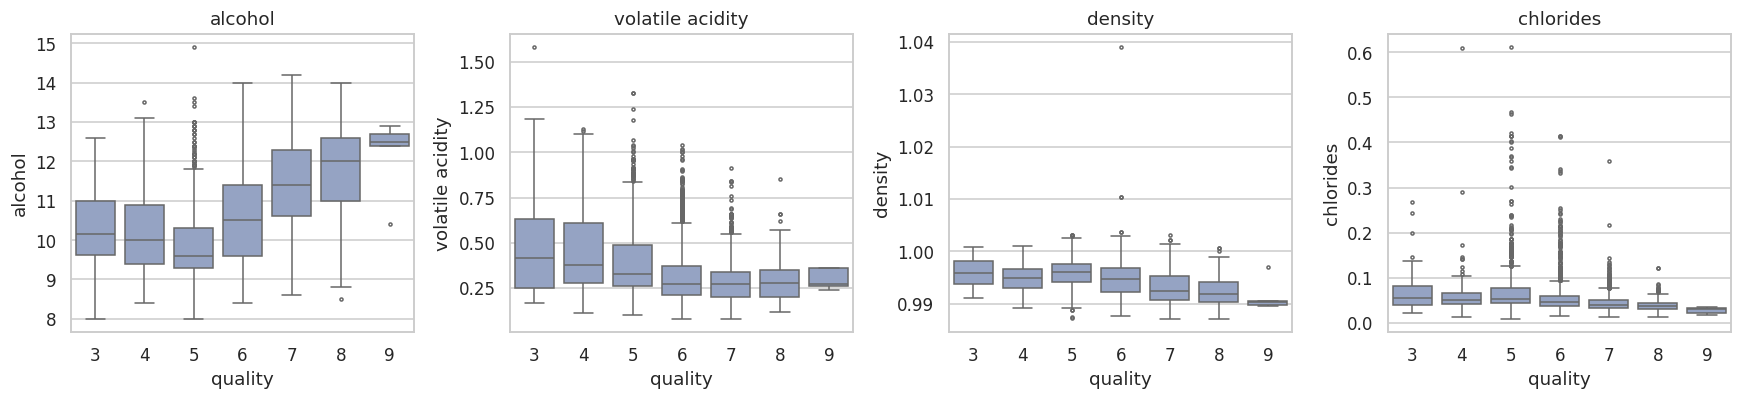

Средние значения признаков по типу вина:
is_red                  белое  красное
fixed acidity           6.855    8.320
volatile acidity        0.278    0.528
citric acid             0.334    0.271
residual sugar          6.391    2.539
chlorides               0.046    0.087
free sulfur dioxide    35.308   15.875
total sulfur dioxide  138.361   46.468
density                 0.994    0.997
pH                      3.188    3.311
sulphates               0.490    0.658
alcohol                10.514   10.423


In [8]:
top = ["alcohol", "volatile acidity", "density", "chlorides"]
fig, axes = plt.subplots(1, 4, figsize=(16, 3.8))
for ax, f in zip(axes, top):
    sns.boxplot(data=df, x="quality", y=f, ax=ax, color="#8DA0CB", fliersize=2)
    ax.set_title(f)
savefig("04_boxplots_by_quality.png"); plt.show()

print("Средние значения признаков по типу вина:")
print(df.groupby("is_red")[num_feats].mean().T.rename(columns={0: "белое", 1: "красное"}).round(3).to_string())


**Вывод.**
* Медианный `alcohol` растёт с ростом оценки начиная с `quality = 5`: ≈ 9.6 → 10.5 → 11.4 → 12.0 → 12.5 (оценки 5…9). Для оценок 3–4 зависимость не монотонна (медианы ≈ 10.0–10.2), но таких вин мало.
* `volatile acidity` убывает от 0.41 (оценка 3) до ≈ 0.27 (оценки 6–9), `density` убывает у хороших вин (0.992 при 7–8 против 0.996 при 5).
* **Но ящики соседних оценок сильно перекрываются.** По химическому составу вина с оценками 5 и 6 (а это 77 % выборки) различаются мало, поэтому задача содержит значительный неустранимый шум (оценка эксперта субъективна, а мы видим только химию). Ожидать от любой модели RMSE около нуля бессмысленно.
* Красное и белое вино отличаются по многим признакам (у красных больше `volatile acidity` — 0.53 против 0.28, `chlorides` — 0.087 против 0.046, `sulphates`; меньше SO₂ и сахара), тогда как разница по `alcohol` и среднему `quality` невелика. Значит, отдельный признак `is_red` в основном избыточен: тип вина виден по остальным показателям.


## 2. Подготовка выборок

In [9]:
X, y = df[FEATURES], df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, random_state=RANDOM_STATE, stratify=y
)
print(f"train: {X_train.shape[0]} ({X_train.shape[0]/len(df):.0%}) | test: {X_test.shape[0]} ({X_test.shape[0]/len(df):.0%})")

dist = pd.DataFrame({"all": y.value_counts(normalize=True), "train": y_train.value_counts(normalize=True),
                     "test": y_test.value_counts(normalize=True)}).sort_index().round(4)
dist["n_test"] = y_test.value_counts().sort_index()
dist

train: 5197 (80%) | test: 1300 (20%)


,all,train,test,n_test
quality,,,,
3,0.0046,0.0046,0.0046,6
4,0.0332,0.0333,0.0331,43
5,0.3291,0.3290,0.3292,428
6,0.4365,0.4366,0.4362,567
7,0.1661,0.1661,0.1662,216
8,0.0297,0.0296,0.0300,39
9,0.0008,0.0008,0.0008,1



**Выбор и обоснование.**
* **Размер:** 80 % / 20 % — обучающая выборка 5197 вин, тестовая 1300. Это стандартный компромисс: 80 % достаточно, чтобы деревьям хватало данных и в редких областях пространства признаков, а 1300 тестовых объектов дают достаточно устойчивую оценку RMSE/MAE. При меньшем тесте оценка заметно «шумела» бы, при большем — страдала бы модель.
* **Способ:** случайное разбиение со **стратификацией по `quality`**. Данные не временные и не имеют групп (идентификатора винодельни или партии нет), поэтому случайное разбиение допустимо. Стратификация нужна из-за редких классов: пропорции оценок в train и test совпадают с исходными с точностью до тысячных долей (таблица выше). Без неё, например, все 5 вин с оценкой 9 могли бы оказаться в одной из частей.
* **`random_state = 42`** зафиксирован в разбиении, моделях и кросс-валидации, весь эксперимент воспроизводим.
* **Дубликаты** (см. раздел 1) при случайном разбиении могут попадать в обе части. Группового разбиения по ним не делалось: это сделало бы тест непохожим на скрытую тестовую выборку, которая, вероятнее всего, формируется так же. Но влияние этого эффекта оценено явно в разделе 8.
* **Подбор гиперпараметров** выполняется только внутри train, через 5-fold кросс-валидацию. Тест не использовался ни для выбора модели, ни для параметров, ни для признаков.

**Что плохого в многократной оценке на одном и том же тесте.**
1. *Смещение отбора («подгонка под тест»).* Если по тесту выбирать лучшую из многих моделей или настроек, то выберется не обязательно лучшая, а та, которой повезло на этих 1300 объектах. Итоговая оценка получится оптимистичной (winner's curse), а на новых данных качество будет хуже.
2. *Информационная утечка через решения.* Модель формально не видит ответов теста, но их видит исследователь, и каждое решение «подкручивает» систему под тест. Чем больше итераций, тем сильнее эффект, тест перестаёт быть независимым.
3. *Ложная значимость различий.* Разница в 0.01 RMSE между моделями на одном тесте может быть просто шумом выборки, а многократные сравнения увеличивают шанс увидеть «улучшение» там, где его нет.

Поэтому для выбора используется кросс-валидация на train, а тест применяется один раз для каждой финальной модели.


## 3. Baseline: одна константа для всех объектов

In [10]:
c_mean = y_train.mean()      # минимизирует MSE/RMSE на обучающей выборке
c_median = y_train.median()  # минимизирует MAE на обучающей выборке

def const_pred(c, n): return np.full(n, c)

baseline_mean = (rmse(y_test, const_pred(c_mean, len(y_test))), mae(y_test, const_pred(c_mean, len(y_test))))
baseline_med = (rmse(y_test, const_pred(c_median, len(y_test))), mae(y_test, const_pred(c_median, len(y_test))))

print(f"Среднее train   = {c_mean:.4f}  -> test RMSE = {baseline_mean[0]:.4f}, MAE = {baseline_mean[1]:.4f}")
print(f"Медиана train   = {c_median:.4f}  -> test RMSE = {baseline_med[0]:.4f}, MAE = {baseline_med[1]:.4f}   (только для сравнения, в итоговую таблицу не входит)")
print(f"\nСтандартное отклонение y_test (= RMSE идеального 'константного' предсказания по test): {y_test.std(ddof=0):.4f}")

Среднее train   = 5.8182  -> test RMSE = 0.8738, MAE = 0.6861
Медиана train   = 6.0000  -> test RMSE = 0.8923, MAE = 0.6377   (только для сравнения, в итоговую таблицу не входит)

Стандартное отклонение y_test (= RMSE идеального 'константного' предсказания по test): 0.8738



**Вывод.**
* Для RMSE оптимальная константа — **среднее** обучающей выборки (5.818): она минимизирует сумму квадратов ошибок. Для MAE оптимальна **медиана** (6). Результат подтверждает это: среднее даёт лучший RMSE (0.874 против 0.892), медиана — лучший MAE (0.638 против 0.686). В итоговую таблицу входит один baseline — **среднее**, так как главная метрика RMSE; медиана посчитана только чтобы обосновать выбор константы.
* RMSE константного предсказания равен стандартному отклонению целевой переменной (0.874). Это «потолок бесполезности»: модель с RMSE ≥ 0.874 не извлекла из признаков ничего полезного.
* Порог задания (RMSE < 0.70) означает, что модель должна объяснять не менее **≈ 36 % дисперсии** целевой переменной (1 − (0.70/0.874)² ≈ 0.36). Для шумной экспертной оценки это содержательное требование, а не формальность.


## 4. Метрики: MAE и RMSE

Пусть $e_i = y_i - \hat y_i$ — ошибка на $i$-м объекте.

$$\mathrm{MAE} = \frac1n\sum_i |e_i| \qquad \mathrm{RMSE} = \sqrt{\frac1n\sum_i e_i^2}$$

* **MAE** — средняя абсолютная ошибка в тех же единицах, что и `quality`. Показывает, на сколько баллов модель ошибается *в среднем*. Все ошибки входят линейно: ошибка в 2 балла «весит» ровно вдвое больше ошибки в 1 балл. Оптимальная константа для MAE — **медиана**.
* **RMSE** — корень из среднего квадрата ошибки, тоже в баллах. Это «типичная» ошибка с акцентом на крупные промахи. Оптимальная константа для RMSE — **среднее**; именно её мы взяли для baseline основной метрики. Для константы из среднего RMSE совпадает со стандартным отклонением целевой переменной.
* **Почему RMSE сильнее реагирует на большие ошибки.** Ошибка возводится в квадрат до усреднения, поэтому ошибка в 3 балла вносит в сумму 9, а три ошибки по 1 балл — только 3. Вклад растёт квадратично, и один крупный промах способен заметно поднять RMSE, почти не затронув MAE.
* **Почему MAE и RMSE различаются у одной модели.** По неравенству между средними всегда $\mathrm{RMSE} \ge \mathrm{MAE}$, причём равенство достигается, только когда все ошибки по модулю одинаковы. Чем неоднороднее ошибки (много маленьких и несколько очень больших), тем больше разрыв. Отношение RMSE/MAE — простой индикатор «тяжести хвоста» распределения ошибок.

In [11]:
# Маленькая иллюстрация: две «модели» с одинаковым MAE, но разной структурой ошибок
e_uniform = np.array([1, 1, 1, 1, 1, 1, 1, 1, 1, 1], dtype=float)   # 10 ошибок по 1 баллу
e_heavy   = np.array([0, 0, 0, 0, 0, 0, 0, 0, 0, 10], dtype=float)  # одна ошибка 10 баллов
for name, e in [("равномерные ошибки", e_uniform), ("одна крупная ошибка", e_heavy)]:
    print(f"{name:>22}: MAE = {np.abs(e).mean():.2f}, RMSE = {np.sqrt((e**2).mean()):.2f}")

    равномерные ошибки: MAE = 1.00, RMSE = 1.00
   одна крупная ошибка: MAE = 1.00, RMSE = 3.16


## 5. Модели

**Общие условия для всех моделей:** одна и та же обучающая/тестовая выборка, один `random_state`, подбор гиперпараметров только по 5-fold кросс-валидации **на обучающей части** (тест для выбора не используется). Тестовая выборка применяется один раз для каждой финальной модели.

In [12]:
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

results = {}   # имя -> dict с метриками
preds = {}     # имя -> предсказания на test

def register(name, y_pred, cv_rmse=np.nan):
    preds[name] = np.asarray(y_pred)
    results[name] = {"RMSE": rmse(y_test, y_pred), "MAE": mae(y_test, y_pred), "CV RMSE (train)": cv_rmse}

# baseline: среднее train (оптимальная константа для RMSE)
register("Baseline (среднее)", const_pred(c_mean, len(y_test)))

### 5.1 Линейная регрессия

In [13]:
lr_raw = LinearRegression().fit(X_train, y_train)                                  # без масштабирования
lr = make_pipeline(StandardScaler(), LinearRegression()).fit(X_train, y_train)     # со стандартизацией

cv_lr = -cross_val_score(lr, X_train, y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
register("Linear Regression", lr.predict(X_test), cv_lr)

print(f"Предсказания raw и scaled совпадают: {np.allclose(lr_raw.predict(X_test), lr.predict(X_test))}")
print(f"Linear Regression: test RMSE = {results['Linear Regression']['RMSE']:.4f}, MAE = {results['Linear Regression']['MAE']:.4f}, CV RMSE = {cv_lr:.4f}")

coef = pd.DataFrame({
    "coef_raw (на единицу признака)": lr_raw.coef_,
    "std признака": X_train.std().values,
    "coef_std (на 1 std)": lr[-1].coef_,
}, index=FEATURES)
coef["|coef_std|"] = coef["coef_std (на 1 std)"].abs()
coef = coef.sort_values("|coef_std|", ascending=False)
coef.round(4)

Предсказания raw и scaled совпадают: True
Linear Regression: test RMSE = 0.7280, MAE = 0.5678, CV RMSE = 0.7377


,coef_raw (на единицу признака),std признака,coef_std (на 1 std),|coef_std|
density,-107.2543,0.0030,-0.3230,0.3230
residual sugar,0.0645,4.7855,0.3086,0.3086
alcohol,0.2152,1.1889,0.2558,0.2558
volatile acidity,-1.4620,0.1658,-0.2423,0.2423
is_red,0.3089,0.4324,0.1335,0.1335
fixed acidity,0.0872,1.2862,0.1121,0.1121
sulphates,0.7447,0.1468,0.1093,0.1093
total sulfur dioxide,-0.0016,56.7384,-0.0909,0.0909
pH,0.5483,0.1607,0.0881,0.0881
free sulfur dioxide,0.0049,17.6470,0.0861,0.0861


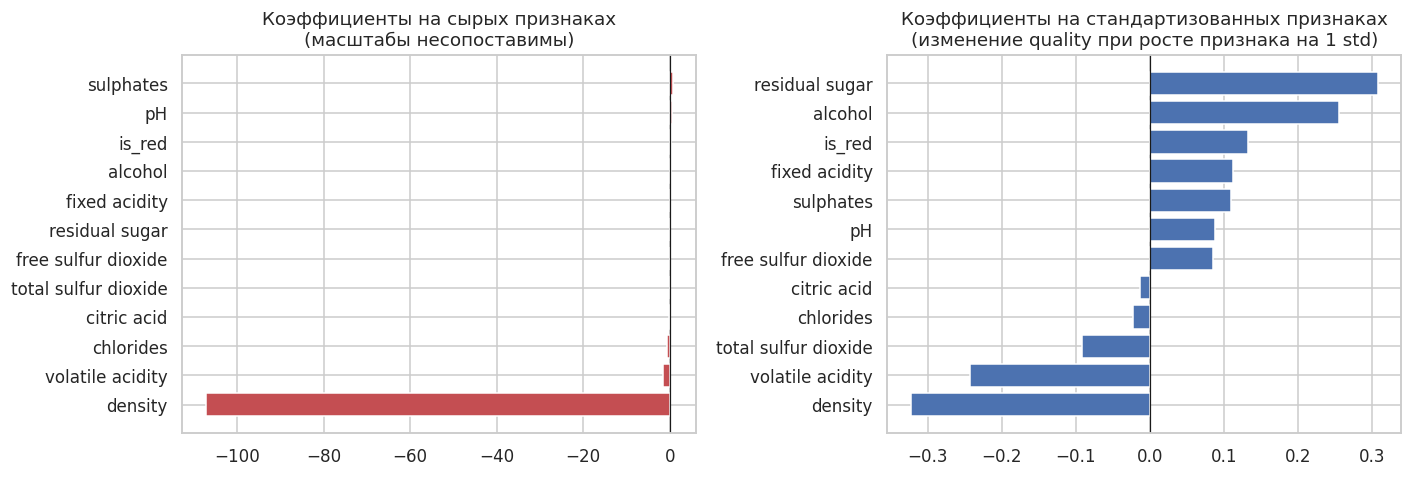

In [14]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
c_raw = coef["coef_raw (на единицу признака)"].sort_values()
ax[0].barh(c_raw.index, c_raw.values, color="#C44E52"); ax[0].set_title("Коэффициенты на сырых признаках\n(масштабы несопоставимы)")
ax[0].axvline(0, color="k", lw=.8)
c_std = coef["coef_std (на 1 std)"].sort_values()
ax[1].barh(c_std.index, c_std.values, color="#4C72B0"); ax[1].set_title("Коэффициенты на стандартизованных признаках\n(изменение quality при росте признака на 1 std)")
ax[1].axvline(0, color="k", lw=.8)
savefig("05_linear_coefficients.png"); plt.show()

In [15]:
# Мультиколлинеарность: VIF_j = 1 / (1 - R^2_j), где R^2_j — регрессия признака j на остальные
def vif_table(Xdf):
    out = {}
    for c in Xdf.columns:
        others = Xdf.drop(columns=c)
        r2 = LinearRegression().fit(others, Xdf[c]).score(others, Xdf[c])
        out[c] = 1 / (1 - r2)
    return pd.Series(out).sort_values(ascending=False)

print("VIF (обучающая выборка):"); print(vif_table(X_train).round(1).to_string())

# Эксперимент: что будет, если убрать density (самый «коллинеарный» признак)? Решение принимаем по CV на train.
feats_nodens = [f for f in FEATURES if f != "density"]
lr_nd = make_pipeline(StandardScaler(), LinearRegression())
cv_nd = -cross_val_score(lr_nd, X_train[feats_nodens], y_train, cv=cv, scoring="neg_root_mean_squared_error").mean()
lr_nd.fit(X_train[feats_nodens], y_train)
print(f"\nCV RMSE с density: {cv_lr:.4f} | без density: {cv_nd:.4f}")
cmp_coef = pd.DataFrame({"с density": lr[-1].coef_, "без density": pd.Series(lr_nd[-1].coef_, index=feats_nodens)}, index=FEATURES)
cmp_coef.loc[["alcohol", "residual sugar", "density", "fixed acidity", "pH"]].round(3)

VIF (обучающая выборка):
density                 21.7
residual sugar           9.7
is_red                   7.1
alcohol                  5.4
fixed acidity            5.0
total sulfur dioxide     4.0
pH                       2.6
free sulfur dioxide      2.2
volatile acidity         2.2
chlorides                1.6
citric acid              1.6
sulphates                1.5

CV RMSE с density: 0.7377 | без density: 0.7407


,с density,без density
alcohol,0.256,0.393
residual sugar,0.309,0.111
density,-0.323,NaN
fixed acidity,0.112,-0.004
pH,0.088,0.020



**Результат.** Linear Regression: RMSE = 0.728, MAE = 0.568 (CV RMSE на train 0.738, то есть тест и кросс-валидация согласуются). Это на **16.7 % лучше baseline** по RMSE, то есть линейная модель действительно извлекает информацию из признаков, но **порог 0.70 не проходит**.

**Масштабирование.**
* На сырых признаках коэффициенты несопоставимы: у `density` он равен −107, у `total sulfur dioxide` — −0.0016. Но это лишь следствие единиц измерения (std плотности 0.003, а SO₂ — 57), а не «важности».
* После `StandardScaler` коэффициент показывает изменение предсказания при росте признака на 1 std и сравним между признаками. Предсказания и качество модели при этом **не меняются** (проверено выше: `allclose = True`), меняется только интерпретация. Для обычной OLS масштабирование не обязательно для точности, но необходимо для сравнения коэффициентов (и было бы обязательным при регуляризации Ridge/Lasso).

**Наибольшее влияние (стандартизованные коэффициенты):** `density` (−0.32), `residual sugar` (+0.31), `alcohol` (+0.26), `volatile acidity` (−0.24), `is_red` (+0.13).

**Но этим коэффициентам нельзя верить буквально.** По EDA `residual sugar` почти не связан с качеством (r ≈ −0.04), а в модели у него второй по величине положительный коэффициент. Причина — мультиколлинеарность: VIF у `density` 21.7, у `residual sugar` 9.7 (значения выше ~5–10 считаются тревожными). Эксперимент это подтверждает: если убрать `density`, качество практически не меняется (CV RMSE 0.738 → 0.741), зато коэффициенты перераспределяются: `alcohol` 0.26 → 0.39, `residual sugar` 0.31 → 0.11, `fixed acidity` 0.11 → ≈ 0. То есть `density` в модели в основном «корректирует» вклад спирта и сахара. Устойчиво интерпретируемы лишь признаки, не втянутые в коллинеарные группы: **`alcohol` (+) и `volatile acidity` (−)**, они сохраняют знак и значимость при любом наборе признаков.

**Почему линейная модель ограничена.** Она предполагает аддитивные линейные эффекты. Если зависимости немонотонны, имеют пороги или взаимодействуют (например, по-разному для красного и белого вина), линейная модель этого не уловит. Различие с лесом (раздел 6) показывает, что в данных такая нелинейность есть. Что будет, если дать линейной модели нелинейные признаки, проверено в разделе 5.1б.


### 5.1б Линейная регрессия с инженерией признаков (Ridge)

Обычная линейная регрессия (раздел 5.1) не проходит порог 0.70 из-за скошенных признаков и нелинейных эффектов. Не меняя класс модели (она остаётся **линейной по параметрам**), можно дать ей более подходящее пространство признаков:
* `log1p` для сильно скошенных признаков (раздел 1.2);
* признак `so2_ratio` = free / total sulfur dioxide (доля свободного SO₂);
* **попарные произведения и квадраты** признаков (`PolynomialFeatures(2)`), включая взаимодействия с `is_red` — так линейная модель получает возможность описывать эффекты «спирт × сахар», «разные режимы для красных и белых вин» и т. п.;
* **Ridge-регуляризацию**, потому что признаков становится 104 и они сильно коррелируют.

Выбор варианта и силы регуляризации — **только по 5-fold CV на train**; на тест смотрим один раз для финальной модели.

In [16]:
SKEWED = ["chlorides", "sulphates", "fixed acidity", "volatile acidity", "residual sugar", "free sulfur dioxide"]

def add_so2_ratio(X):
    X = X.copy()
    X["so2_ratio"] = X["free sulfur dioxide"] / X["total sulfur dioxide"]
    return X

def make_lr_plus(poly=True, ratio=True, log=True):
    steps = []
    if ratio: steps.append(("ratio", FunctionTransformer(add_so2_ratio)))
    if log:   steps.append(("log", ColumnTransformer([("log", FunctionTransformer(np.log1p), SKEWED)], remainder="passthrough")))
    steps.append(("s1", StandardScaler()))
    if poly:  steps += [("poly", PolynomialFeatures(2, include_bias=False)), ("s2", StandardScaler())]
    steps.append(("ridge", Ridge()))
    return Pipeline(steps)

# Какой вклад вносит каждый шаг? Сравнение по CV на train (alpha подбирается внутри для каждого варианта)
variants = {
    "OLS без преобразований":          (False, False, False),
    "+ log1p скошенных":               (False, False, True),
    "+ log1p + so2_ratio":             (False, True, True),
    "+ log1p + квадратичные признаки": (True, False, True),
    "+ log1p + so2_ratio + квадратичные": (True, True, True),
}
rows = []
for name, (p_, r_, l_) in variants.items():
    g_ = GridSearchCV(make_lr_plus(p_, r_, l_), {"ridge__alpha": [0.01, 1, 3, 10, 30, 100]},
                      cv=cv, scoring="neg_root_mean_squared_error").fit(X_train, y_train)
    rows.append({"вариант": name, "alpha": g_.best_params_["ridge__alpha"], "CV RMSE (train)": -g_.best_score_})
lr_variants = pd.DataFrame(rows).set_index("вариант")
print(lr_variants.round(4).to_string())

best_variant = lr_variants["CV RMSE (train)"].idxmin()
print("\nЛучший вариант по CV:", best_variant)
p_, r_, l_ = variants[best_variant]
lr_plus_grid = GridSearchCV(make_lr_plus(p_, r_, l_), {"ridge__alpha": [0.1, 0.3, 1, 3, 10, 30, 100]},
                            cv=cv, scoring="neg_root_mean_squared_error", refit=True).fit(X_train, y_train)
lr_plus = lr_plus_grid.best_estimator_

LR_PLUS = "Linear Regression + признаки (Ridge)"
register(LR_PLUS, lr_plus.predict(X_test), -lr_plus_grid.best_score_)
n_feats = lr_plus[:-1].transform(X_train.head(2)).shape[1]
print(f"alpha = {lr_plus_grid.best_params_['ridge__alpha']}, число признаков после преобразований = {n_feats}")
print(f"{LR_PLUS}: test RMSE = {results[LR_PLUS]['RMSE']:.4f}, MAE = {results[LR_PLUS]['MAE']:.4f}, CV RMSE = {-lr_plus_grid.best_score_:.4f}")
print(f"Порог RMSE < 0.70 выполнен на тесте: {results[LR_PLUS]['RMSE'] < 0.70}")

                                    alpha  CV RMSE (train)
вариант                                                   
OLS без преобразований                 30           0.7376
+ log1p скошенных                     100           0.7313
+ log1p + so2_ratio                    30           0.7315
+ log1p + квадратичные признаки        10           0.7023
+ log1p + so2_ratio + квадратичные      3           0.7001

Лучший вариант по CV: + log1p + so2_ratio + квадратичные


alpha = 3, число признаков после преобразований = 104
Linear Regression + признаки (Ridge): test RMSE = 0.6938, MAE = 0.5421, CV RMSE = 0.7001
Порог RMSE < 0.70 выполнен на тесте: True



**Результат.** Расширенная линейная модель (log1p скошенных признаков + доля свободного SO₂ + квадраты и попарные произведения + Ridge) даёт **test RMSE ≈ 0.694, MAE ≈ 0.542** (CV RMSE на train ≈ 0.700), то есть **проходит порог 0.70**, тогда как обычная OLS давала 0.728.

**Откуда улучшение** (см. таблицу вариантов выше, там сравнение по CV на train): основной вклад вносят квадратичные признаки и взаимодействия, то есть возможность описывать нелинейные и совместные эффекты; логарифмирование скошенных признаков и `so2_ratio` дают небольшую добавку. Ridge нужен для устойчивости: из 12 исходных признаков получается 104, и многие из них сильно скоррелированы. Это подтверждает вывод раздела 5.1: ограничение обычной линейной регрессии связано не с «слабыми» признаками, а с тем, что зависимости нелинейны и взаимосвязаны.

**Честные оговорки.**
* **Запас над порогом минимален.** CV RMSE ≈ 0.700, а разброс по фолдам ≈ 0.016, то есть на другой тестовой выборке результат вполне может оказаться чуть выше 0.70. Говорить, что «линейная модель надёжно проходит порог», нельзя; корректнее — «находится на границе».
* **Это уже не «простая» линейная регрессия** с интерпретируемыми коэффициентами: 104 признака, коэффициенты при них отдельно не интерпретируются. Для анализа коэффициентов и feature importance в разделе 7 использована обычная линейная регрессия из раздела 5.1.
* **Случайный лес по-прежнему заметно лучше** (RMSE 0.593 против 0.694): деревья ловят пороговые эффекты и локальную структуру, которую полином второй степени описывает лишь приближённо (пробовались и сплайны, и степень 3, но лучшего CV они не дали).
* Выбор варианта и `alpha` сделан по CV на train; тест использован один раз для финальной модели.


### 5.2 Random Forest Regressor

In [17]:
rf_grid = GridSearchCV(
    RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1),
    param_grid={"n_estimators": [300], "max_features": [0.33, 0.6], "min_samples_leaf": [1, 2]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
).fit(X_train, y_train)
rf = rf_grid.best_estimator_

register("Random Forest", rf.predict(X_test), -rf_grid.best_score_)
print("Лучшие параметры:", rf_grid.best_params_)
print(f"Random Forest: test RMSE = {results['Random Forest']['RMSE']:.4f}, MAE = {results['Random Forest']['MAE']:.4f}, CV RMSE = {-rf_grid.best_score_:.4f}")
pd.DataFrame(rf_grid.cv_results_)[["param_max_features", "param_min_samples_leaf", "mean_test_score", "std_test_score"]].assign(
    cv_rmse=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(4)

Лучшие параметры: {'max_features': 0.33, 'min_samples_leaf': 1, 'n_estimators': 300}
Random Forest: test RMSE = 0.5932, MAE = 0.4247, CV RMSE = 0.6130


,param_max_features,param_min_samples_leaf,std_test_score,cv_rmse
0,0.33,1,0.0136,0.6130
1,0.33,2,0.0118,0.6246
2,0.60,1,0.0111,0.6164
3,0.60,2,0.0102,0.6236


### 5.3 Gradient Boosting Regressor

In [18]:
gb_grid = GridSearchCV(
    GradientBoostingRegressor(random_state=RANDOM_STATE),
    param_grid={"n_estimators": [300], "learning_rate": [0.05, 0.1], "max_depth": [4, 6], "subsample": [0.8]},
    cv=cv, scoring="neg_root_mean_squared_error", n_jobs=1, refit=True,
).fit(X_train, y_train)
gb = gb_grid.best_estimator_

register("Gradient Boosting", gb.predict(X_test), -gb_grid.best_score_)
print("Лучшие параметры:", gb_grid.best_params_)
print(f"Gradient Boosting: test RMSE = {results['Gradient Boosting']['RMSE']:.4f}, MAE = {results['Gradient Boosting']['MAE']:.4f}, CV RMSE = {-gb_grid.best_score_:.4f}")
pd.DataFrame(gb_grid.cv_results_)[["param_learning_rate", "param_max_depth", "mean_test_score", "std_test_score"]].assign(
    cv_rmse=lambda d: -d["mean_test_score"]).drop(columns="mean_test_score").round(4)

Лучшие параметры: {'learning_rate': 0.1, 'max_depth': 6, 'n_estimators': 300, 'subsample': 0.8}
Gradient Boosting: test RMSE = 0.6212, MAE = 0.4472, CV RMSE = 0.6360


,param_learning_rate,param_max_depth,std_test_score,cv_rmse
0,0.05,4,0.0123,0.6667
1,0.05,6,0.0131,0.6366
2,0.10,4,0.0155,0.6579
3,0.10,6,0.0148,0.6360


## 6. Честное сравнение моделей

In [19]:
res = pd.DataFrame(results).T
res["Улучшение RMSE vs baseline"] = 1 - res["RMSE"] / res.loc["Baseline (среднее)", "RMSE"]
res["Лучше baseline по RMSE"] = res["RMSE"] < res.loc["Baseline (среднее)", "RMSE"]
res["RMSE < 0.70"] = res["RMSE"] < 0.70
res["RMSE/MAE"] = res["RMSE"] / res["MAE"]
res.index.name = "Модель"
res.round(4).to_csv(RES_DIR / "metrics.csv")

main_table = res[["RMSE", "MAE"]].round(4)
print("Итоговая таблица (одна и та же тестовая выборка, n =", len(y_test), "):\n")
print(main_table.to_string())
print()
res[["CV RMSE (train)", "Улучшение RMSE vs baseline", "Лучше baseline по RMSE", "RMSE < 0.70", "RMSE/MAE"]].round(4)

Итоговая таблица (одна и та же тестовая выборка, n = 1300 ):

                                        RMSE     MAE
Модель                                              
Baseline (среднее)                    0.8738  0.6861
Linear Regression                     0.7280  0.5678
Linear Regression + признаки (Ridge)  0.6938  0.5421
Random Forest                         0.5932  0.4247
Gradient Boosting                     0.6212  0.4472



,CV RMSE (train),Улучшение RMSE vs baseline,Лучше baseline по RMSE,RMSE < 0.70,RMSE/MAE
Модель,,,,,
Baseline (среднее),NaN,0.0000,False,False,1.2736
Linear Regression,0.7377,0.1669,True,False,1.2821
Linear Regression + признаки (Ridge),0.7001,0.2060,True,True,1.2798
Random Forest,0.6130,0.3211,True,True,1.3967
Gradient Boosting,0.6360,0.2891,True,True,1.3892


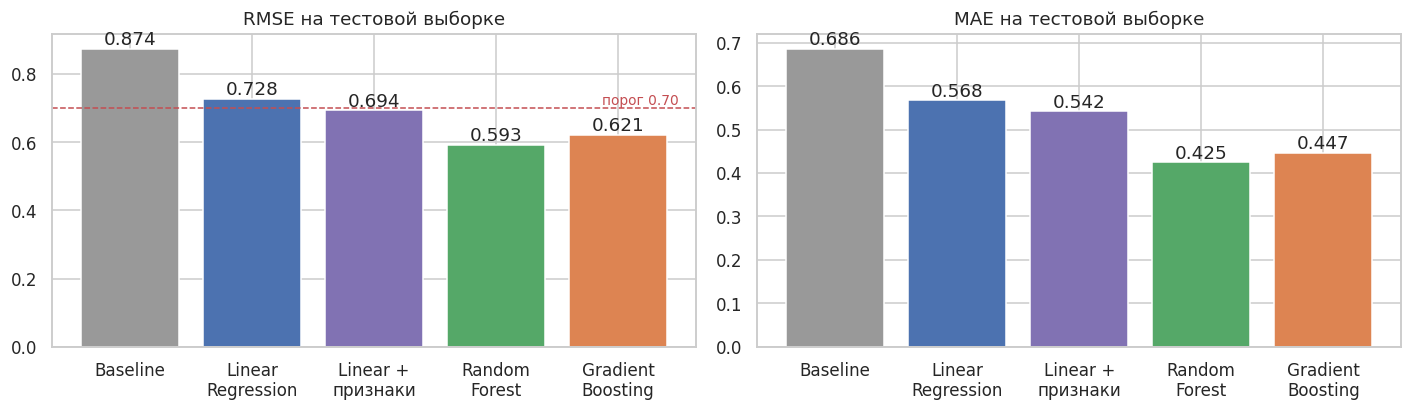

In [20]:
order = ["Baseline (среднее)", "Linear Regression", LR_PLUS, "Random Forest", "Gradient Boosting"]
fig, ax = plt.subplots(1, 2, figsize=(13, 3.9))
for a, m in zip(ax, ["RMSE", "MAE"]):
    vals = res.loc[order, m]
    bars = a.bar(range(len(order)), vals.values, color=["#999999", "#4C72B0", "#8172B3", "#55A868", "#DD8452"])
    a.set_xticks(range(len(order))); a.set_xticklabels(["Baseline", "Linear\nRegression", "Linear +\nпризнаки", "Random\nForest", "Gradient\nBoosting"])
    a.set_title(f"{m} на тестовой выборке"); a.bar_label(bars, fmt="%.3f")
    if m == "RMSE":
        a.axhline(0.70, color="r", ls="--", lw=1); a.text(len(order) - .5, 0.71, "порог 0.70", color="r", ha="right", fontsize=9)
savefig("06_model_comparison.png"); plt.show()


**Итоговая таблица** (тест, n = 1300, одна и та же выборка и метрики для всех моделей):

| Модель | RMSE | MAE |
|---|---|---|
| Baseline (среднее train) | 0.8738 | 0.6861 |
| Linear Regression (обычная) | 0.7280 | 0.5678 |
| Linear Regression + признаки (Ridge) | 0.6938 | 0.5421 |
| Random Forest | **0.5932** | **0.4247** |
| Gradient Boosting | 0.6212 | 0.4472 |

**Кто превзошёл baseline.** По RMSE — все модели: обычная линейная регрессия на 16.7 %, расширенная линейная на 20.6 %, градиентный бустинг на 28.9 %, случайный лес на 32.1 %. По MAE — тоже все. **Порог RMSE < 0.70 проходят Random Forest, Gradient Boosting и расширенная линейная регрессия (0.694, с очень малым запасом); обычная линейная регрессия (0.728) — нет.**

**Почему результаты различаются.**
* **Линейная регрессия → ансамбли деревьев (0.728 → 0.59–0.62).** Часть разрыва закрывается и для линейной модели, если дать ей нелинейные признаки (0.694, раздел 5.1б), но остаток остаётся. Основная причина — нелинейность и взаимодействия признаков, которые линейная модель принципиально не описывает: пороговые эффекты (SO₂, кислотность), разные «режимы» для красных и белых вин, связь `alcohol` — `density` — `residual sugar`. Подтверждение из раздела 7: деревья считают важными `free`/`total sulfur dioxide`, которые по линейной корреляции с quality почти незаметны. Кроме того, деревья устойчивы к скошенности и выбросам, на которых линейная модель теряет точность.
* **Random Forest vs Gradient Boosting (0.593 vs 0.621).** Вероятные причины: (1) данные небольшие (≈ 5200 строк) и **шумные** (субъективная оценка): усреднение независимых глубоких деревьев в лесу эффективно снижает дисперсию, тогда как бустинг последовательно «доучивает» остатки и при глубоких деревьях склонен подстраиваться под шум; (2) разрыв устойчив, а не случаен: он наблюдается и на CV (0.613 против 0.636), и на тесте, и больше, чем разброс по фолдам (std ≈ 0.01–0.015); (3) честная оговорка — лучшая конфигурация бустинга лежит **на границе сетки** (`max_depth = 6`, `learning_rate = 0.1`), так что при более широком поиске (глубже, больше деревьев, ранняя остановка) разрыв мог бы сократиться. Мы ограничили сетку из-за вычислительных ресурсов; это не меняет вывода, что в заданных условиях лучше лес.
* **Отношение RMSE/MAE** у леса (1.40) и бустинга (1.39) выше, чем у линейной модели (1.28): ансамбли дают много очень точных предсказаний и несколько крупных промахов (на редких оценках, см. раздел 8), у линейной модели ошибки более однородны, но в среднем крупнее. Лучший RMSE у леса не означает отсутствия тяжёлого хвоста ошибок.
* **Оговорка об оценке (подробно в разделе 8).** Часть преимущества глубоких деревьев (`min_samples_leaf = 1`) связана с тем, что ≈ 27 % тестовых вин имеют точный дубль в обучающей выборке, и дерево может его «запомнить». Для вин без дубля RMSE леса заметно выше.


## 7. Feature importance

Для трёх моделей получаем важность признаков разными способами:

* **Linear Regression** — модуль коэффициента при *стандартизованном* признаке (изменение предсказания при росте признака на одно стандартное отклонение);
* **Random Forest и Gradient Boosting** — встроенная важность (MDI, суммарное уменьшение impurity по всем разбиениям, нормированное на 1);
* **Permutation importance** — рост RMSE при случайном перемешивании значений одного признака. Считается на тесте **уже после** выбора и обучения моделей, только для анализа; на выбор модели и параметров он не влиял. Метод не страдает от смещения MDI в сторону признаков с большим числом уникальных значений.

In [21]:
imp = pd.DataFrame(index=FEATURES)
imp["LinReg |coef_std|"] = np.abs(lr[-1].coef_) / np.abs(lr[-1].coef_).sum()
imp["RF (MDI)"] = rf.feature_importances_
imp["GB (MDI)"] = gb.feature_importances_

perm = {}
for name, model in [("RF", rf), ("GB", gb)]:
    r = permutation_importance(model, X_test, y_test, scoring="neg_root_mean_squared_error",
                               n_repeats=10, random_state=RANDOM_STATE, n_jobs=1)
    perm[name] = pd.DataFrame({"mean": r.importances_mean, "std": r.importances_std}, index=FEATURES)
imp["RF (permutation, ΔRMSE)"] = perm["RF"]["mean"]
imp["GB (permutation, ΔRMSE)"] = perm["GB"]["mean"]
imp = imp.sort_values("RF (MDI)", ascending=False)
imp.round(4).to_csv(RES_DIR / "feature_importance.csv")
imp.round(4)

,LinReg |coef_std|,RF (MDI),GB (MDI),"RF (permutation, ΔRMSE)","GB (permutation, ΔRMSE)"
alcohol,0.1433,0.1760,0.2309,0.1736,0.1635
volatile acidity,0.1357,0.1097,0.1293,0.0822,0.0847
density,0.1809,0.1070,0.0744,0.0530,0.0626
free sulfur dioxide,0.0482,0.0845,0.0881,0.0709,0.0892
chlorides,0.0123,0.0828,0.0615,0.0394,0.0287
total sulfur dioxide,0.0509,0.0787,0.0821,0.0451,0.0925
residual sugar,0.1729,0.0755,0.0800,0.0375,0.0602
sulphates,0.0612,0.0746,0.0765,0.0514,0.0607
citric acid,0.0076,0.0722,0.0549,0.0371,0.0359
pH,0.0493,0.0696,0.0641,0.0250,0.0348


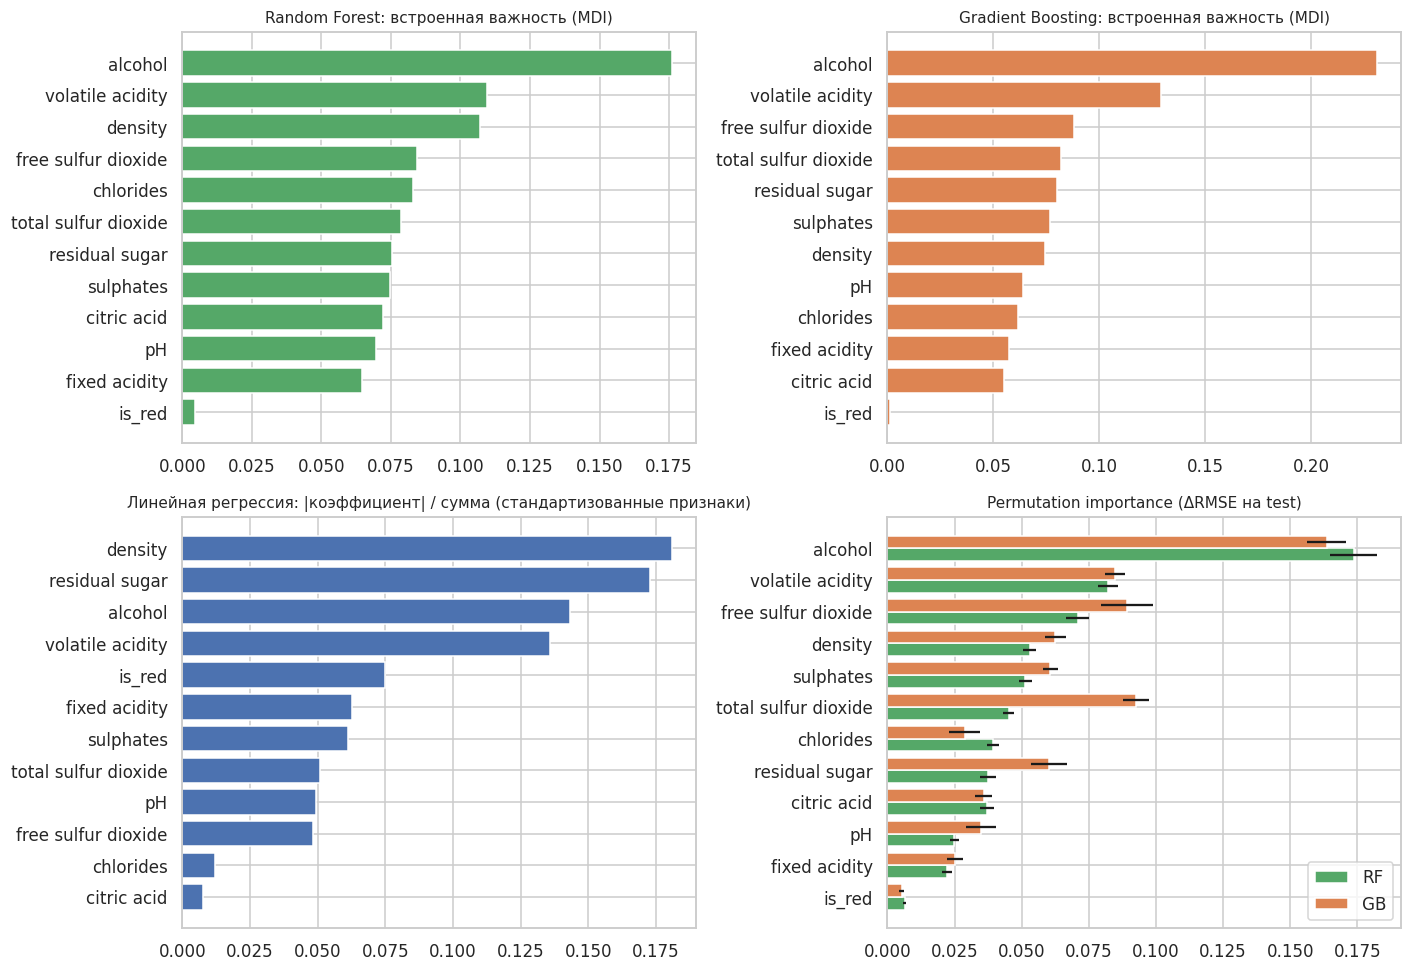

In [22]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for a, (col, title, color) in zip(axes.ravel(), [
        ("RF (MDI)", "Random Forest: встроенная важность (MDI)", "#55A868"),
        ("GB (MDI)", "Gradient Boosting: встроенная важность (MDI)", "#DD8452"),
        ("LinReg |coef_std|", "Линейная регрессия: |коэффициент| / сумма (стандартизованные признаки)", "#4C72B0"),
        (None, "Permutation importance (ΔRMSE на test)", None)]):
    if col is not None:
        s = imp[col].sort_values()
        a.barh(s.index, s.values, color=color)
    else:
        s_rf = perm["RF"].sort_values("mean")
        idx = s_rf.index
        h = 0.4; ypos = np.arange(len(idx))
        a.barh(ypos - h/2, perm["RF"].loc[idx, "mean"], h, xerr=perm["RF"].loc[idx, "std"], color="#55A868", label="RF")
        a.barh(ypos + h/2, perm["GB"].loc[idx, "mean"], h, xerr=perm["GB"].loc[idx, "std"], color="#DD8452", label="GB")
        a.set_yticks(ypos); a.set_yticklabels(idx); a.legend()
    a.set_title(title, fontsize=10)
savefig("07_feature_importance.png"); plt.show()

In [23]:
# Сопоставление рангов важности между методами и с EDA (|корреляция Спирмена| с quality)
rank_tbl = pd.DataFrame({
    "EDA |Spearman|": sp.abs(),
    "LinReg": imp["LinReg |coef_std|"],
    "RF (MDI)": imp["RF (MDI)"],
    "GB (MDI)": imp["GB (MDI)"],
    "RF (perm)": imp["RF (permutation, ΔRMSE)"],
    "GB (perm)": imp["GB (permutation, ΔRMSE)"],
}).loc[FEATURES]
ranks = rank_tbl.rank(ascending=False).astype(int).sort_values("RF (MDI)")
print("Ранги признаков (1 = самый важный):"); print(ranks.to_string())
print("\nКорреляция рангов (Спирмен) между методами:")
print(rank_tbl.corr(method="spearman").round(2).to_string())
print("\nТоп-5 по каждому методу:")
for c in rank_tbl.columns:
    print(f"  {c:<16}", ", ".join(rank_tbl[c].sort_values(ascending=False).index[:5]))

Ранги признаков (1 = самый важный):
                      EDA |Spearman|  LinReg  RF (MDI)  GB (MDI)  RF (perm)  GB (perm)
alcohol                            1       3         1         1          1          1
volatile acidity                   4       4         2         2          2          4
density                            2       1         3         7          4          5
free sulfur dioxide                8      10         4         3          3          3
chlorides                          3      11         5         9          7         10
total sulfur dioxide               9       8         6         4          6          2
residual sugar                    12       2         7         5          8          7
sulphates                         11       7         8         6          5          6
citric acid                        6      12         9        11          9          8
pH                                10       9        10         8         10          9
fixed a


**Что видно по графикам и таблицам рангов.**
* **`alcohol` — самый важный признак в каждой из четырёх оценок для деревьев** (MDI: 0.18 у леса и 0.23 у бустинга; permutation: перемешивание `alcohol` увеличивает RMSE на ≈ 0.17, это в 2–4 раза больше, чем у остальных признаков). На втором месте стабильно **`volatile acidity`** (ранг 2 в обоих MDI, ранг 2 и 4 по permutation). Эти два вывода полностью согласуются с EDA (alcohol и volatile acidity вошли в четвёрку сильнейших по связи с quality) и с линейной регрессией (там они тоже в топ-4 по модулю).
* **Расхождения с EDA и линейной моделью — самое интересное:**
  * `free sulfur dioxide` и `total sulfur dioxide` у деревьев занимают места со 2-го по 6-е (чаще 3–4-е), а по EDA они на 8–9 месте (|Спирмен| 0.09 и 0.06). Значит, их влияние нелинейно или проявляется во взаимодействиях (например, слишком мало свободного SO₂ — риск окисления, слишком много — вкусовой дефект), и корреляция Пирсона/Спирмена его не видит. Это содержательное объяснение выигрыша деревьев над линейной моделью.
  * `density` — 1-й по линейной модели и 2-й по EDA, но 3-й (лес) и 7-й (бустинг) по MDI: её информация в основном дублируется `alcohol` и `residual sugar` (r = −0.69 и +0.55). Если `alcohol` уже использован, дерево реже берёт `density`, и важность делится между скоррелированными признаками произвольным образом.
  * `chlorides`: 3-й по EDA, 11-й по линейной модели, 5–10-й по деревьям. Связь с quality есть, но во многом объясняется другими признаками (в том числе типом вина).
  * `is_red` — последний у деревьев (MDI 0.005 и 0.001): информацию о типе вина они уже получают из SO₂, `volatile acidity`, `chlorides`. Линейной модели признак нужен (5-е место), так как она не умеет вывести его из других признаков нелинейно.
* **Согласованность методов.** Лес и бустинг сильно согласованы между собой (Спирмен рангов 0.8–0.94, MDI и permutation вместе), а линейная модель с ними почти не согласована (0.2–0.34) и с EDA тоже (≈ 0.2). Устойчивое «ядро» важных признаков: **`alcohol`, `volatile acidity`, `free`/`total sulfur dioxide`** (и в меньшей степени `density`, `sulphates`). Хвост (`fixed acidity`, `pH`, `citric acid`, `is_red`) устойчиво неважен.
* **Методологическая оговорка.** MDI и permutation могут давать разные ранги: у бустинга по permutation `total sulfur dioxide` оказывается 2-м, по MDI — 4-м. Причина в сильной корреляции free/total SO₂ (r = 0.72): при перемешивании одного из них создаются нереалистичные комбинации, и падение качества может быть завышено. Поэтому выводы строились по совпадению нескольких методов, а не по одному.

### Можно ли по feature importance утверждать, что признак является *причиной* качества вина?

**Нет.** Важность признака отвечает на вопрос «насколько модель опирается на этот признак для прогноза на данных, которые мы наблюдали», а не «что произойдёт с оценкой, если мы изменим признак». Причины:
1. **Скрытые общие причины (confounding).** Высокий `alcohol` может быть следствием спелости винограда, сорта, региона, технологии, ценовой категории, а оценка эксперта зависит от тех же факторов. Модель видит корреляцию, а не механизм: возможно, что и спирт, и оценка вызваны третьим фактором.
2. **Корреляция признаков.** Важность делится между скоррелированными признаками (как с `density` выше), поэтому важность признака зависит от того, какие ещё признаки есть в наборе, и не измеряет его собственный вклад. Физически нельзя изменить спирт, не меняя плотность.
3. **Нет направления и формы.** Importance — неотрицательное число: оно не говорит, повышает признак качество или понижает, и тем более какой ценой.
4. **Зависимость от модели и метода.** Ранги у линейной регрессии, леса и бустинга, MDI и permutation заметно различаются, тогда как причинность не может зависеть от выбранного алгоритма.
5. **Наблюдательные данные.** Это не эксперимент: никто не менял признак при прочих равных. Возможна и обратная связь (производитель целенаправленно делает «премиальные» вина более крепкими).
6. **Целевая переменная — субъективная оценка**, на неё влияют неизмеренные факторы (вкус, аромат, бренд), которых в датасете нет.

Feature importance — инструмент для **формирования гипотез** («стоит проверить роль спирта и летучей кислотности»). Для причинных выводов нужны контролируемые эксперименты (например, слепая дегустация вин, отличающихся только одним показателем) или специальные методы причинного вывода с явными допущениями.


## 8. Анализ ошибок лучшей модели

Лучшая модель по CV RMSE на train: Random Forest
Её test RMSE / MAE: 0.5932 / 0.4247


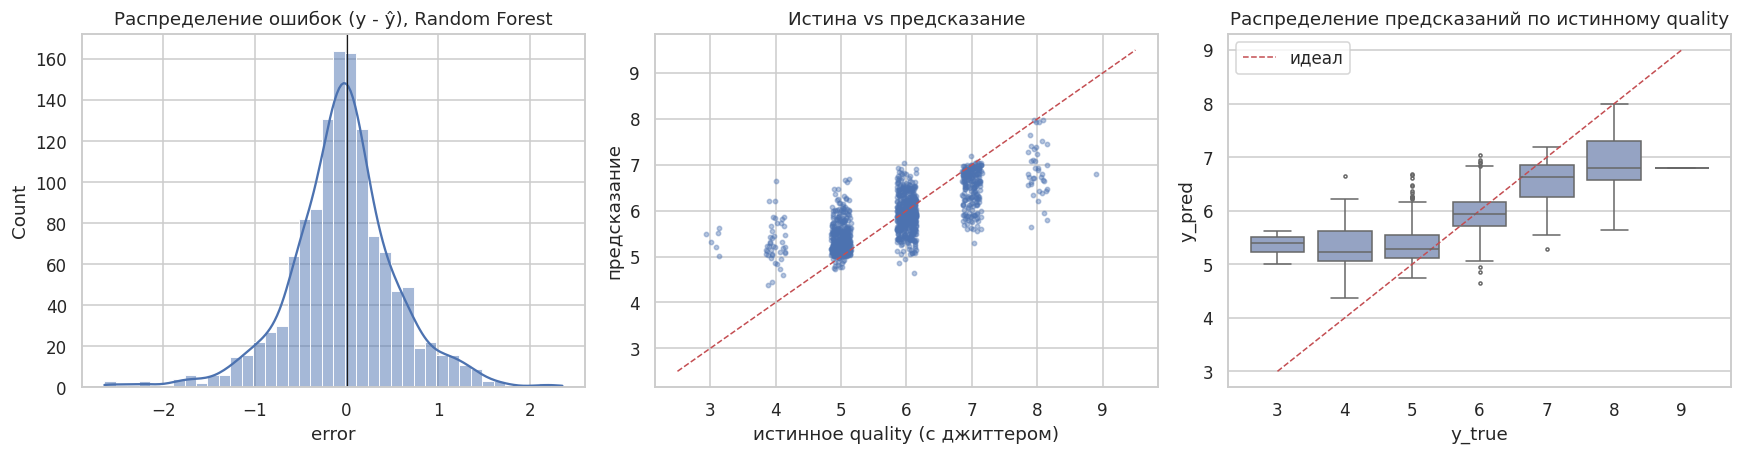

Среднее ошибки (bias): -0.0387 | std: 0.5922 | асимметрия: -0.21
Доля объектов с |ошибкой| <= 0.5: 68.8%
Доля объектов с |ошибкой| <= 1.0: 90.1%
Доля объектов с |ошибкой| <= 1.5: 97.5%
Доля точных попаданий после округления предсказания: 68.5%


In [24]:
# Лучшая модель выбирается по CV RMSE на обучающей выборке (не по тесту)
cands = ["Linear Regression", LR_PLUS, "Random Forest", "Gradient Boosting"]
best_name = min(cands, key=lambda m: results[m]["CV RMSE (train)"])
print("Лучшая модель по CV RMSE на train:", best_name)
print("Её test RMSE / MAE:", round(results[best_name]['RMSE'], 4), "/", round(results[best_name]['MAE'], 4))

best_pred = preds[best_name]
err = pd.DataFrame({"y_true": y_test.values, "y_pred": best_pred}, index=y_test.index)
err["error"] = err["y_true"] - err["y_pred"]          # >0: модель занижает оценку
err["abs_error"] = err["error"].abs()
err["is_red"] = X_test["is_red"].values

fig, ax = plt.subplots(1, 3, figsize=(16, 4.3))
sns.histplot(err["error"], bins=40, kde=True, ax=ax[0], color="#4C72B0")
ax[0].axvline(0, color="k", lw=.8); ax[0].set_title(f"Распределение ошибок (y - ŷ), {best_name}")
rng = np.random.default_rng(RANDOM_STATE)
ax[1].scatter(err["y_true"] + rng.uniform(-.15, .15, len(err)), err["y_pred"], s=8, alpha=.4, color="#4C72B0")
ax[1].plot([2.5, 9.5], [2.5, 9.5], "r--", lw=1); ax[1].set_xlabel("истинное quality (с джиттером)"); ax[1].set_ylabel("предсказание"); ax[1].set_title("Истина vs предсказание")
sns.boxplot(data=err, x="y_true", y="y_pred", ax=ax[2], color="#8DA0CB", fliersize=2)
ax[2].plot(range(len(sorted(err.y_true.unique()))), sorted(err.y_true.unique()), "r--", lw=1, label="идеал")
ax[2].set_title("Распределение предсказаний по истинному quality"); ax[2].legend()
savefig("08_error_analysis.png"); plt.show()

print(f"Среднее ошибки (bias): {err['error'].mean():+.4f} | std: {err['error'].std():.4f} | асимметрия: {err['error'].skew():+.2f}")
for t in [0.5, 1.0, 1.5]:
    print(f"Доля объектов с |ошибкой| <= {t}: {(err['abs_error'] <= t).mean():.1%}")
print(f"Доля точных попаданий после округления предсказания: {(np.rint(err['y_pred']) == err['y_true']).mean():.1%}")

In [25]:
by_q = err.groupby("y_true").agg(n=("error", "size"), MAE=("abs_error", "mean"),
                                 RMSE=("error", lambda e: np.sqrt((e**2).mean())),
                                 bias=("error", "mean"), mean_pred=("y_pred", "mean")).round(3)
by_q["доля train"] = y_train.value_counts(normalize=True).sort_index().reindex(by_q.index).round(4)
print("Качество по истинным значениям quality (bias = среднее y - ŷ; >0 значит модель занижает):")
print(by_q.to_string())

by_t = err.groupby(err["is_red"].map({1: "красное", 0: "белое"})).agg(n=("error", "size"), MAE=("abs_error", "mean"),
        RMSE=("error", lambda e: np.sqrt((e**2).mean())), bias=("error", "mean")).round(3)
print("\nПо типу вина:"); print(by_t.to_string())

# Насколько «легко» тест пересекается с train: есть ли в train вина с точно таким же вектором признаков?
key = lambda d: d[FEATURES].round(6).astype(str).agg("|".join, axis=1)
train_keys = set(key(X_train))
test_in_train = key(X_test).isin(train_keys)
print(f"\nДоля тестовых объектов, чей вектор признаков полностью совпадает с вином из train: {test_in_train.mean():.1%}")
for lbl, m in [("с дублем в train", test_in_train.values), ("без дубля в train", ~test_in_train.values)]:
    e_ = err.loc[m, "error"]
    print(f"  {lbl:<18} n = {m.sum():>4} | RMSE = {np.sqrt((e_**2).mean()):.3f} | MAE = {e_.abs().mean():.3f}")

# Вклад редких оценок (3, 4, 8, 9) в суммарную квадратичную ошибку
rare = err["y_true"].isin([3, 4, 8, 9])
print(f"\nРедкие оценки (3, 4, 8, 9): {rare.mean():.1%} объектов test дают {(err.loc[rare, 'error']**2).sum() / (err['error']**2).sum():.1%} суммы квадратов ошибок")

Качество по истинным значениям quality (bias = среднее y - ŷ; >0 значит модель занижает):
          n    MAE   RMSE   bias  mean_pred  доля train
y_true                                                 
3         6  2.358  2.368 -2.358      5.358      0.0046
4        43  1.313  1.390 -1.313      5.313      0.0333
5       428  0.387  0.506 -0.377      5.377      0.3290
6       567  0.293  0.379  0.058      5.942      0.4366
7       216  0.486  0.629  0.482      6.518      0.1661
8        39  1.093  1.234  1.093      6.907      0.0296
9         1  2.210  2.210  2.210      6.790      0.0008

По типу вина:
           n    MAE   RMSE   bias
is_red                           
белое    994  0.423  0.590 -0.068
красное  306  0.430  0.602  0.056



Доля тестовых объектов, чей вектор признаков полностью совпадает с вином из train: 27.5%
  с дублем в train   n =  357 | RMSE = 0.218 | MAE = 0.162
  без дубля в train  n =  943 | RMSE = 0.684 | MAE = 0.524

Редкие оценки (3, 4, 8, 9): 6.8% объектов test дают 39.6% суммы квадратов ошибок



**Вывод.** Лучшая модель, выбранная **по CV на train** (а не по тесту), — Random Forest: RMSE 0.593, MAE 0.425.

*Общая картина ошибок.* Распределение ошибок близко к симметричному колоколу с центром около нуля (смещение −0.04), но с тяжёлыми хвостами: 69 % предсказаний отличаются от истины не более чем на 0.5 балла, 90 % — не более чем на 1, 97.5 % — не более чем на 1.5. Именно небольшая доля крупных ошибок и даёт RMSE/MAE = 1.40.

*Качество неодинаково для разных значений `quality` — главное наблюдение этого раздела:*
* **Центр (оценки 5 и 6, 77 % выборки):** MAE 0.39 и 0.29 — здесь модель работает хорошо.
* **Оценка 7:** MAE 0.49, систематическое занижение (bias +0.48).
* **Редкие хвосты:** оценка 3 — MAE 2.36, оценка 4 — 1.31, оценка 8 — 1.09, оценка 9 — 2.21. Знак смещения везде один и тот же: хорошие вина занижаются, плохие завышаются. Средний прогноз для истинных оценок 3 и 4 равен ≈ 5.3, для оценки 8 — 6.9: **модель «сжимает» диапазон к середине** (на графике справа предсказания лежат почти в полосе 5–7, тогда как истинные значения от 3 до 9).
* Редкие оценки (3, 4, 8, 9) составляют всего ≈ 7 % тестовых объектов, но дают ≈ 40 % суммы квадратов ошибок — общий RMSE во многом определяется небольшим числом трудных вин.
* По типу вина качество одинаково (MAE 0.42 для белых и 0.43 для красных): систематического перекоса между типами нет.

*Почему модель хуже предсказывает редкие значения:*
1. **Мало примеров.** В train всего ≈ 24 вина с оценкой 3 и 4 вина с оценкой 9; дереву не из чего выучить закономерность для этих областей.
2. **Усреднение и квадратичная ошибка.** Лес предсказывает среднее по обучающим объектам в листьях. Если в «плохой» области пространства признаков рядом оказываются вина с оценками 3, 4, 5 и 6, среднее будет ≈ 5, и крайние значения почти не выдаются. Предсказание дерева — среднее обучающих значений, поэтому оно не выходит за их диапазон, а при MSE-критерии «смелый» прогноз редкой оценки, оказавшийся неверным, обходится слишком дорого.
3. **Перекрытие классов по признакам.** Как показали боксплоты, по химическому составу вино с оценкой 3–4 часто неотличимо от вина с оценкой 5–6: не хватает информации (вкус, аромат, сорт), а не только данных.
4. **Шум оценок.** Оценка эксперта субъективна; одна «случайно» низкая оценка у химически обычного вина — шум, предсказать который невозможно.

*Оговорка про дубликаты.* У **27.5 %** тестовых вин вектор признаков полностью совпадает с вином из train. На них модель почти не ошибается (RMSE 0.22, MAE 0.16), на остальных 72.5 % RMSE равен **0.68**, MAE 0.52 (см. вывод ячейки выше). То есть для действительно «новых» вин качество заметно ниже общего и лишь немного лучше порога 0.70 (запас небольшой). Метрика на тесте остаётся честной в смысле процедуры (тест не использовался при выборе), но она отражает долю «знакомых» вин в выборке. Для скрытой тестовой выборки, сформированной аналогичным способом, ожидается похожий эффект; если же она не содержит дублей из train, RMSE следует ожидать ближе к 0.68.


In [26]:
# Самые крупные ошибки: сравним признаки объекта с типичными значениями train (z-score)
mu, sd = X_train.mean(), X_train.std()
top_err = err.sort_values("abs_error", ascending=False).head(10)
show = pd.concat([top_err[["y_true", "y_pred", "error"]].round(2), X_test.loc[top_err.index, ["alcohol", "volatile acidity", "total sulfur dioxide", "is_red"]].round(2)], axis=1)
print("Топ-10 ошибок:"); print(show.to_string())

z = ((X_test.loc[top_err.index, num_feats] - mu[num_feats]) / sd[num_feats])
print("\nПризнаки, сильно отличающиеся от обычных (|z| > 2.5), для этих объектов:")
for i in top_err.index:
    ext = z.loc[i][z.loc[i].abs() > 2.5].round(1)
    print(f"  idx {i:>5} (истина {int(err.loc[i,'y_true'])}, прогноз {err.loc[i,'y_pred']:.2f}): " + (", ".join(f"{k}={v:+.1f}σ" for k, v in ext.items()) or "типичные значения признаков"))

Топ-10 ошибок:
      y_true  y_pred  error  alcohol  volatile acidity  total sulfur dioxide  is_red
6107       4    6.64  -2.64     11.5              0.26                 129.0       0
2339       3    5.62  -2.62     12.6              0.39                  19.0       0
1850       3    5.52  -2.52      9.8              0.26                 197.0       0
3287       3    5.49  -2.49      9.4              0.25                 216.0       0
3005       8    5.64   2.36     10.5              0.22                  90.0       0
1374       3    5.31  -2.31      9.8              0.82                  29.0       1
5369       4    6.22  -2.22     12.0              0.27                 143.0       0
3715       4    6.21  -2.21     11.7              0.20                  68.0       0
2426       9    6.79   2.21     12.5              0.24                 139.0       0
1469       3    5.20  -2.20      9.7              0.98                  49.0       1

Признаки, сильно отличающиеся от обычных (|z| > 2


**Вывод по самым крупным ошибкам.** Все 10 ошибок по модулю составляют 2.2–2.6 балла. **8 из 10 — вина с истинной оценкой 3 или 4**, которые модель предсказывает как «обычные» (5.2–6.6), ещё два — отличные вина (оценки 8 и 9), которые модель недооценивает (5.6 и 6.8). То есть крупнейшие промахи — это выбросы по целевой переменной, а не по признакам.

Возможные причины на примерах:
* **Признаки типичны, но оценка нет (idx 2339, 1850, 6107, 5369, 3715, 3005, 2426).** У большинства из них |z| < 2.5 по всем признакам, то есть химия выглядит как у обычного вина. Например, вина 6107, 5369, 3715 (истина 4) и 2339 (истина 3) имеют высокий `alcohol` (11.5–12.6) и обычную `volatile acidity` (0.20–0.39): модель, опираясь на правило «крепкое → в среднем лучше», предсказывает 5.6–6.6. Причина низкой оценки лежит вне измеренных показателей: дефект вкуса или аромата (окисление, пробковый тон), сорт, индивидуальное мнение эксперта. Никакая модель на этих 11 признаках причину увидеть не может.
* **Вино 2426 (истина 9, прогноз 6.79).** Оценка 9 встречается в датасете всего 5 раз (4 в train), прогноз упирается в максимум того, что видели деревья; экстраполировать до 9 они не способны. Аналогично 3005 (истина 8, прогноз 5.64): химически вино без выраженных признаков «выдающегося», о его оценке по этим данным ничего не сказать.
* **Вина 1374 и 1469 (красные, истина 3).** Здесь признаки действительно необычны: `volatile acidity` +2.9σ / +3.9σ, у 1374 ещё `chlorides` +6.1σ. Модель двигается в правильную сторону (прогнозы 5.31 и 5.20 заметно ниже среднего 5.8), но не доходит до 3: таких вин мало, и в листьях они смешаны с соседями, у которых оценка 5.
* **Вино 3287 (истина 3, прогноз 5.49):** аномально высокий `free sulfur dioxide` (+5σ) — область пространства признаков с единичными наблюдениями, надёжной закономерности деревья там не выучили.

**Как можно улучшить поведение на хвостах** (за рамками задания): веса объектов или oversampling редких оценок, функция потерь, менее чувствительная к «среднему» (квантильная), признаки-взаимодействия (например, доля свободного SO₂ от общего), раздельные модели для красных и белых вин, ординальная постановка. Главное ограничение — информационное: у модели нет вкусовых и ароматических признаков.


## 9. Итоговые выводы


### Итоги

| Модель | RMSE | MAE | Лучше baseline | RMSE < 0.70 |
|---|---|---|---|---|
| Baseline (среднее) | 0.874 | 0.686 | — | нет |
| Linear Regression (обычная) | 0.728 | 0.568 | да | **нет** |
| Linear Regression + признаки (Ridge) | 0.694 | 0.542 | да | да (на границе) |
| **Random Forest** | **0.593** | **0.425** | да | да |
| Gradient Boosting | 0.621 | 0.447 | да | да |

1. **Лучшая модель — Random Forest** (RMSE 0.593 < 0.70; на 32 % лучше baseline), выбрана по кросс-валидации на обучающей выборке; тест использован один раз для финальной оценки.
2. **Данные содержат неустранимый шум**: оценки 5–6 составляют 77 % выборки и почти не разделяются химией; потолок качества ограничен субъективностью экспертной оценки.
3. **Ключевые признаки**: `alcohol` (безусловный лидер), `volatile acidity`, `free`/`total sulfur dioxide`, отчасти `density`. EDA и линейная модель видят только линейную часть картины, деревья дополнительно выявили роль SO₂ (нелинейный эффект). Importance не доказывает причинности.
4. **Линейная модель** ограничена мультиколлинеарностью (VIF `density` 21.7) и нелинейностью; коэффициенты при `density`/`residual sugar` неустойчивы, а надёжно трактуются только `alcohol` (+) и `volatile acidity` (−). Добавление log-преобразований, взаимодействий и Ridge доводит её до RMSE ≈ 0.694, но ценой интерпретируемости и с минимальным запасом над порогом.
5. **Ошибки распределены неравномерно**: центр (5–6) предсказывается хорошо, редкие 3, 4, 8, 9 — плохо (модель «сжимает» диапазон к среднему); ≈ 7 % объектов дают ≈ 40 % квадратичной ошибки.

### Ограничения и честные оговорки
* **Дубликаты:** у 27.5 % тестовых вин в train есть точная копия. На «новых» винах RMSE леса 0.68 (общий 0.59), порог пройден, но с небольшим запасом.
* **Единственное разбиение:** оценка получена на одном разбиении (random_state = 42), и разброс оценки от конкретного разбиения не измерялся (при желании это делается повторным разбиением или repeated CV).
* **Сетки гиперпараметров небольшие** (из-за времени вычислений); у бустинга лучший вариант на границе сетки, поэтому его потенциал мог быть недооценён.
* **Данные объединены** (красное + белое с признаком `is_red`). Если скрытая тестовая выборка содержит только один тип вина, метрики могут отличаться.
* Выбросы и скошенность не обрабатывались, чтобы условия для всех моделей были одинаковыми.
